Saved → drawdown_djia.png   (n=5,809, mean=1.34%, max=22.0%)


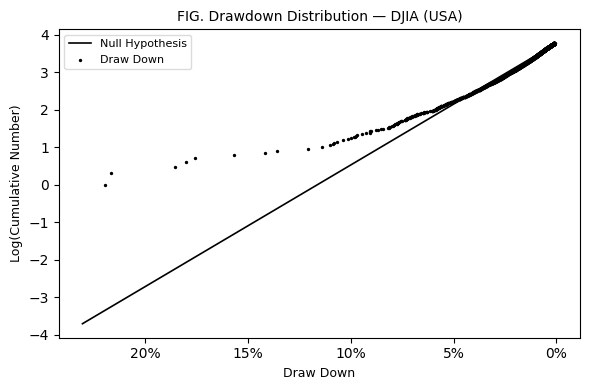

Saved → drawdown_nasdaq.png   (n=1,880, mean=1.35%, max=14.0%)


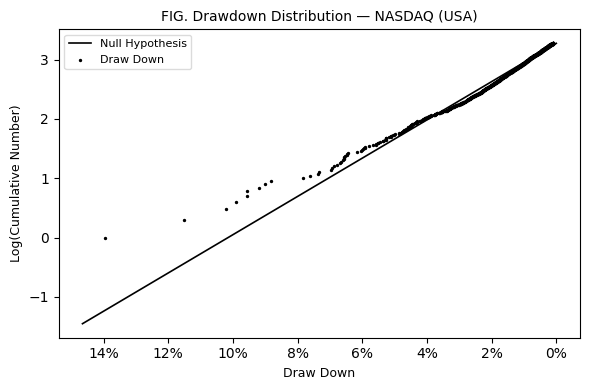

Saved → drawdown_ftse.png   (n=2,341, mean=1.23%, max=16.3%)


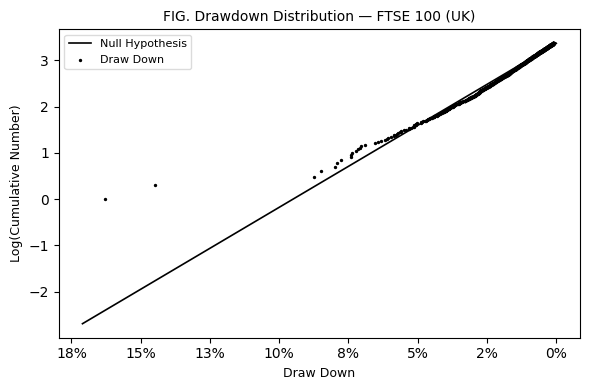

Saved → drawdown_cac.png   (n=1,858, mean=1.38%, max=19.5%)


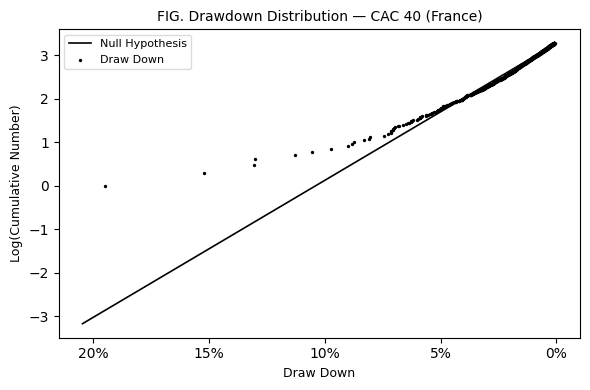

Saved → drawdown_dax.png   (n=1,837, mean=1.37%, max=17.8%)


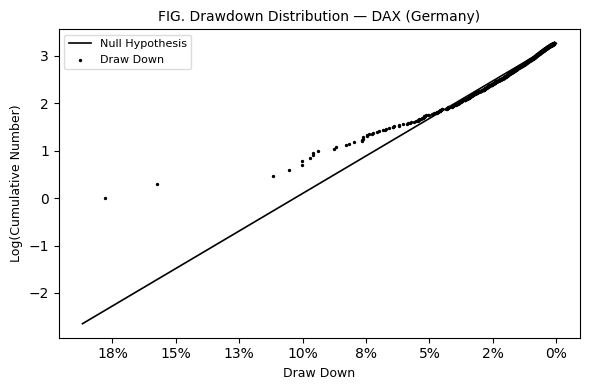

Saved → drawdown_mibtel.png   (n=1,383, mean=1.50%, max=37.1%)


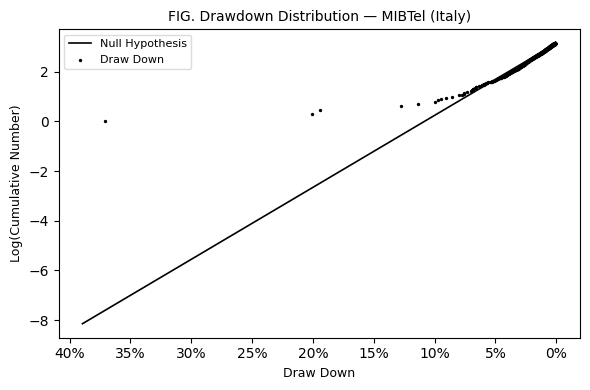

In [4]:
"""
Drawdown Distribution Analysis — Sornette (2003)
One figure per market, styled like the book.

To add more markets, just add entries to the MARKETS dict.
To use real data, replace simulate_returns() with yfinance (see bottom).
"""

import numpy as np
import matplotlib.pyplot as plt

MARKETS = {
    "DJIA (USA)":      dict(sigma=0.0063, n=25000),
    "NASDAQ (USA)":    dict(sigma=0.0095, n=8000),
    "FTSE 100 (UK)":   dict(sigma=0.0075, n=10000),
    "CAC 40 (France)": dict(sigma=0.0080, n=8000),
    "DAX (Germany)":   dict(sigma=0.0085, n=8000),
    "MIBTel (Italy)":  dict(sigma=0.0072, n=6000),
}


def simulate_returns(n, sigma, seed=42):
    rng = np.random.default_rng(seed)
    returns, vol = [], sigma
    for _ in range(n):
        z = rng.standard_t(4) / np.sqrt(2)
        r = z * vol
        returns.append(r)
        vol = np.sqrt(1e-6 + 0.05 * r**2 + 0.94 * vol**2)
    return np.array(returns)


def get_drawdowns(returns):
    drawdowns = []
    i = 0
    while i < len(returns):
        if returns[i] < 0:
            depth = 0.0
            while i < len(returns) and returns[i] < 0:
                depth += returns[i]
                i += 1
            if abs(depth) > 0.001:
                drawdowns.append(abs(depth))
        else:
            i += 1
    return np.array(drawdowns)


for idx, (name, cfg) in enumerate(MARKETS.items()):

    returns   = simulate_returns(cfg["n"], cfg["sigma"], seed=idx)
    drawdowns = np.sort(get_drawdowns(returns))[::-1]
    N         = len(drawdowns)

    log_cum = np.log10(np.arange(1, N + 1))

    # Exponential null hypothesis line
    lam    = 1.0 / np.mean(drawdowns)
    x_line = np.linspace(0, drawdowns.max() * 1.05, 300)
    y_line = np.log10(N) - lam * x_line / np.log(10)

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(x_line, y_line, color="black", lw=1.2, label="Null Hypothesis")
    ax.scatter(drawdowns, log_cum, s=8, color="black", marker=".", label="Draw Down")

    ax.invert_xaxis()
    ax.set_title(f"FIG. Drawdown Distribution — {name}", fontsize=10)
    ax.set_xlabel("Draw Down", fontsize=9)
    ax.set_ylabel("Log(Cumulative Number)", fontsize=9)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x*100:.0f}%"))
    ax.legend(fontsize=8, framealpha=0.7)
    ax.grid(False)

    fig.tight_layout()
    fname = f"drawdown_{name.split()[0].lower()}.png"
    fig.savefig(fname, dpi=150, bbox_inches="tight", facecolor="white")
    print(f"Saved → {fname}   (n={N:,}, mean={np.mean(drawdowns)*100:.2f}%, max={drawdowns.max()*100:.1f}%)")
    plt.show()

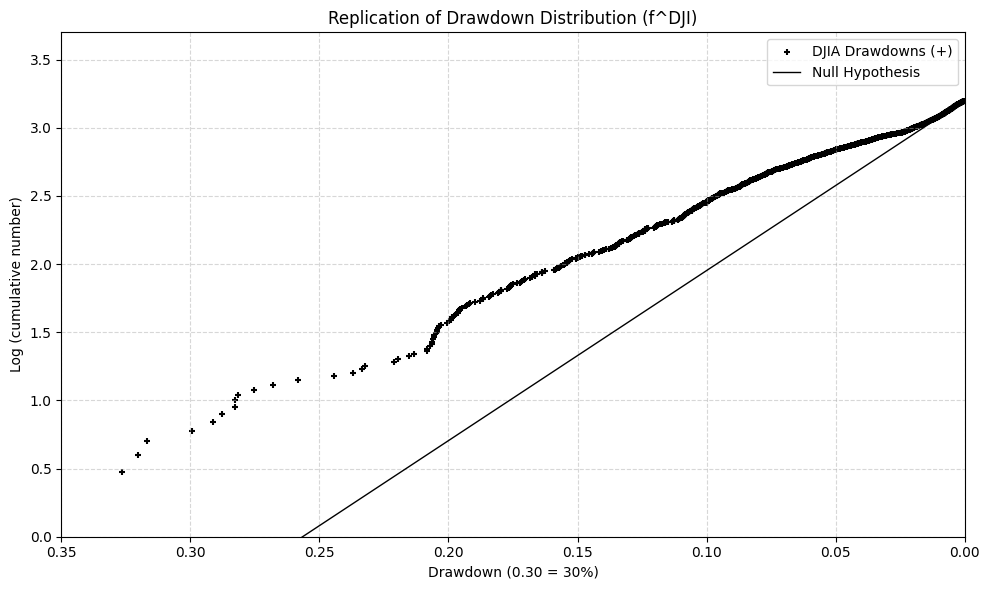

In [2]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt

# 1. Fetch historical data for the Dow Jones (^DJI)
# Using a long period to capture the major crashes mentioned in the text
ticker_ = "^DJI"
ticker = yf.Ticker(ticker_)
data = ticker.history(period="7y")['Close']

# 2. Calculate Drawdowns
# Drawdown = (Current Value / Running Maximum) - 1
running_max = data.cummax()
drawdowns = (data / running_max) - 1

# Filter for only negative movements (actual drawdowns) 
# and take the absolute value for plotting
drawdown_events = np.abs(drawdowns[drawdowns < 0])

# 3. Prepare Cumulative Distribution Data
# Sort drawdowns to calculate the "Number of times a level was observed"
sorted_drawdowns = np.sort(drawdown_events)
n = len(sorted_drawdowns)
# Cumulative count (rank) from largest to smallest
cumulative_count = np.arange(n, 0, -1)

# 4. Fit the Null Hypothesis (Exponential)
# We use the mean of the smaller drawdowns to define the decay (per the text)
mean_drawdown = np.mean(drawdown_events[drawdown_events < 0.10])

# --- Plotting ---
plt.figure(figsize=(10, 6))

# Plot the Empirical Data (+)
plt.scatter(sorted_drawdowns, np.log10(cumulative_count), 
            marker='+', color='black', s=15, label='DJIA Drawdowns (+)')

# Plot the Null Hypothesis (Straight line in log-space)
# Log10(N * exp(-x/lambda)) = Log10(N) - (x/lambda * log10(e))
x_range = np.linspace(0, 0.35, 100)
null_hypo = np.log10(n) - (x_range / mean_drawdown) * np.log10(np.exp(1))
plt.plot(x_range, null_hypo, color='black', linewidth=1, label='Null Hypothesis')

# Formatting to match the provided images
plt.title(f"Replication of Drawdown Distribution (f{ticker_})")
plt.xlabel("Drawdown (0.30 = 30%)")
plt.ylabel("Log (cumulative number)")
plt.xlim(0.35, 0)  # Invert X-axis as seen in Fig 3.4/3.7
plt.ylim(0, np.log10(n) + 0.5)
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()